In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]
df = pd.read_csv(
    "data/data_banknote_authentication.txt",
    header=None,
    names=column_names
)
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1372, 5)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


In [4]:
X = df.drop("class", axis=1).values
y = df["class"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst sample's features:", X[0])
print("First sample's class:", y[0])

X shape: (1372, 4)
y shape: (1372,)

First sample's features: [ 3.6216   8.6661  -2.8073  -0.44699]
First sample's class: 0


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1097, 4)
X_test: (275, 4)
y_train: (1097,)
y_test: (275,)


In [6]:

def gini_impurity(labels):
    if len(labels) == 0:
        return 0.0

    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / len(labels)

    return 1 - np.sum(probabilities ** 2)


In [7]:

print("Pure group:", gini_impurity(np.array([0, 0, 0, 0])))
print("Mixed group:", gini_impurity(np.array([0, 0, 1, 1])))
print("Uneven group:", gini_impurity(np.array([0, 0, 0, 1])))


Pure group: 0.0
Mixed group: 0.5
Uneven group: 0.375


In [8]:

def weighted_gini(left_labels, right_labels):
    n_left = len(left_labels)
    n_right = len(right_labels)
    n_total = n_left + n_right

    if n_total == 0:
        return 0.0

    left_weight = n_left / n_total
    right_weight = n_right / n_total

    return (
        left_weight * gini_impurity(left_labels)
        + right_weight * gini_impurity(right_labels)
    )


left = np.array([0, 0, 0, 0, 1])
right = np.array([0, 0, 1, 1, 1])
parent = np.concatenate([left, right])

print("Parent Gini:", gini_impurity(parent))
print("Weighted child Gini:", weighted_gini(left, right))
print(
    "Gini gain:",
    gini_impurity(parent) - weighted_gini(left, right)
)


Parent Gini: 0.48
Weighted child Gini: 0.3999999999999999
Gini gain: 0.08000000000000007


In [9]:

def evaluate_split(X, y, feature_index, threshold):
    feature_values = X[:, feature_index]

    left_mask = feature_values <= threshold
    right_mask = feature_values > threshold

    left_labels = y[left_mask]
    right_labels = y[right_mask]

    # Reject splits that leave one side empty.
    if len(left_labels) == 0 or len(right_labels) == 0:
        return None

    parent_gini = gini_impurity(y)
    child_gini = weighted_gini(left_labels, right_labels)
    gain = parent_gini - child_gini

    return {
        "feature_index": feature_index,
        "threshold": threshold,
        "left_count": len(left_labels),
        "right_count": len(right_labels),
        "weighted_gini": child_gini,
        "gini_gain": gain
    }


In [10]:

result = evaluate_split(
    X_train,
    y_train,
    feature_index=0,
    threshold=2.0
)

print(result)


{'feature_index': 0, 'threshold': 2.0, 'left_count': 732, 'right_count': 365, 'weighted_gini': np.float64(0.30853361381437366), 'gini_gain': np.float64(0.18538325069303824)}


In [11]:

def find_best_split(X, y):
    best_split = None
    best_gain = -1.0

    n_features = X.shape[1]

    for feature_index in range(n_features):
        values = np.unique(X[:, feature_index])
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            result = evaluate_split(
                X, y, feature_index, threshold
            )

            if result is not None and result["gini_gain"] > best_gain:
                best_gain = result["gini_gain"]
                best_split = result

    return best_split


In [12]:

best_split = find_best_split(X_train, y_train)

print("Best split:")
print(best_split)


Best split:
{'feature_index': 0, 'threshold': np.float64(0.7651), 'left_count': 593, 'right_count': 504, 'weighted_gini': np.float64(0.25182235494123956), 'gini_gain': np.float64(0.24209450956617234)}


In [13]:

from collections import Counter

class DecisionTreeScratch:
    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    def _majority_class(self, y):
        counts = Counter(y)
        return counts.most_common(1)[0][0]

    def _build_tree(self, X, y, depth):
        majority = self._majority_class(y)
        if len(np.unique(y)) == 1:
            return {"prediction": majority}
        if depth >= self.max_depth:
            return {"prediction": majority}

        if len(y) < self.min_samples_split:
            return {"prediction": majority}
        split = find_best_split(X, y)
        if split is None or split["gini_gain"] <= 0:
            return {"prediction": majority}

        feature = split["feature_index"]
        threshold = split["threshold"]

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask
        left_child = self._build_tree(
            X[left_mask], y[left_mask], depth + 1
        )
        right_child = self._build_tree(
            X[right_mask], y[right_mask], depth + 1
        )

        return {
            "feature": feature,
            "threshold": threshold,
            "left": left_child,
            "right": right_child,
            "prediction": majority
        }

    def fit(self, X, y):
        self.tree = self._build_tree(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        # Leaf node: return its prediction
        if "feature" not in node:
            return node["prediction"]

        feature = node["feature"]
        threshold = node["threshold"]

        if x[feature] <= threshold:
            return self._predict_one(x, node["left"])

        return self._predict_one(x, node["right"])

    def predict(self, X):
        return np.array([
            self._predict_one(x, self.tree) for x in X
        ])


In [14]:

tree = DecisionTreeScratch(
    max_depth=5,
    min_samples_split=2
)

tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)

print("First 10 actual labels:", y_test[:10])
print("First 10 predictions:  ", y_pred[:10])
print("Test accuracy:", np.mean(y_pred == y_test))


First 10 actual labels: [0 1 0 1 1 1 0 0 0 1]
First 10 predictions:   [0 1 0 1 1 1 0 0 0 1]
Test accuracy: 0.9854545454545455


In [15]:

correct = (y_test == y_pred)

print("Total test samples:", len(y_test))
print("Correct predictions:", np.sum(correct))
print("Incorrect predictions:", np.sum(~correct))
print("Accuracy (%):", np.mean(correct) * 100)

print("\nIncorrect predictions:")
print("Actual labels:   ", y_test[~correct])
print("Predicted labels:", y_pred[~correct])


Total test samples: 275
Correct predictions: 271
Incorrect predictions: 4
Accuracy (%): 98.54545454545455

Incorrect predictions:
Actual labels:    [0 0 0 0]
Predicted labels: [1 1 1 1]


In [16]:

wrong_indices = np.where(y_test != y_pred)[0]

for i in wrong_indices:
    print(f"\nTest sample index: {i}")
    print("Features:", X_test[i])
    print("Actual class:", y_test[i])
    print("Predicted class:", y_pred[i])



Test sample index: 103
Features: [1.1558 6.4003 1.5506 0.6961]
Actual class: 0
Predicted class: 1

Test sample index: 117
Features: [1.0191  2.33    4.9334  0.82929]
Actual class: 0
Predicted class: 1

Test sample index: 123
Features: [-0.64472 -4.6062   8.347   -2.7099 ]
Actual class: 0
Predicted class: 1

Test sample index: 165
Features: [2.0193  0.82356 4.6369  1.4202 ]
Actual class: 0
Predicted class: 1


In [17]:

def print_tree(node, feature_names, indent=""):
    if "feature" not in node:
        print(indent + f"Predict class: {node['prediction']}")
        return

    feature = feature_names[node["feature"]]
    threshold = node["threshold"]

    print(f"{indent}IF {feature} <= {threshold:.4f}:")
    print_tree(node["left"], feature_names, indent + "  ")

    print(f"{indent}ELSE ({feature} > {threshold:.4f}):")
    print_tree(node["right"], feature_names, indent + "  ")


feature_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy"
]

print_tree(tree.tree, feature_names)


IF variance <= 0.7651:
  IF skewness <= 5.1608:
    IF variance <= 0.3202:
      IF curtosis <= 6.2187:
        IF skewness <= 4.0941:
          Predict class: 1
        ELSE (skewness > 4.0941):
          Predict class: 1
      ELSE (curtosis > 6.2187):
        IF skewness <= -3.3067:
          Predict class: 1
        ELSE (skewness > -3.3067):
          Predict class: 0
    ELSE (variance > 0.3202):
      IF curtosis <= 0.4701:
        Predict class: 1
      ELSE (curtosis > 0.4701):
        IF entropy <= 0.7187:
          Predict class: 0
        ELSE (entropy > 0.7187):
          Predict class: 1
  ELSE (skewness > 5.1608):
    IF variance <= -3.4311:
      IF curtosis <= 2.1114:
        Predict class: 1
      ELSE (curtosis > 2.1114):
        Predict class: 0
    ELSE (variance > -3.4311):
      IF curtosis <= -4.5013:
        Predict class: 1
      ELSE (curtosis > -4.5013):
        Predict class: 0
ELSE (variance > 0.7651):
  IF curtosis <= -4.4558:
    IF variance <= 3.3041:
 

In [18]:

def trace_sample(x, node, feature_names):
    while "feature" in node:
        feature = node["feature"]
        threshold = node["threshold"]
        value = x[feature]

        if value <= threshold:
            print(
                f"{feature_names[feature]} = {value:.4f} "
                f"<= {threshold:.4f} : LEFT"
            )
            node = node["left"]
        else:
            print(
                f"{feature_names[feature]} = {value:.4f} "
                f"> {threshold:.4f} : RIGHT"
            )
            node = node["right"]

    print("Leaf prediction:", node["prediction"])


for i in wrong_indices:
    print(f"\n--- Test sample {i} ---")
    print("Actual class:", y_test[i])
    trace_sample(X_test[i], tree.tree, feature_names)



--- Test sample 103 ---
Actual class: 0
variance = 1.1558 > 0.7651 : RIGHT
curtosis = 1.5506 > -4.4558 : RIGHT
variance = 1.1558 <= 1.7439 : LEFT
curtosis = 1.5506 > -2.2859 : RIGHT
entropy = 0.6961 > 0.6282 : RIGHT
Leaf prediction: 1

--- Test sample 117 ---
Actual class: 0
variance = 1.0191 > 0.7651 : RIGHT
curtosis = 4.9334 > -4.4558 : RIGHT
variance = 1.0191 <= 1.7439 : LEFT
curtosis = 4.9334 > -2.2859 : RIGHT
entropy = 0.8293 > 0.6282 : RIGHT
Leaf prediction: 1

--- Test sample 123 ---
Actual class: 0
variance = -0.6447 <= 0.7651 : LEFT
skewness = -4.6062 <= 5.1608 : LEFT
variance = -0.6447 <= 0.3202 : LEFT
curtosis = 8.3470 > 6.2187 : RIGHT
skewness = -4.6062 <= -3.3067 : LEFT
Leaf prediction: 1

--- Test sample 165 ---
Actual class: 0
variance = 2.0193 > 0.7651 : RIGHT
curtosis = 4.6369 > -4.4558 : RIGHT
variance = 2.0193 > 1.7439 : RIGHT
variance = 2.0193 <= 2.0366 : LEFT
variance = 2.0193 > 2.0171 : RIGHT
Leaf prediction: 1


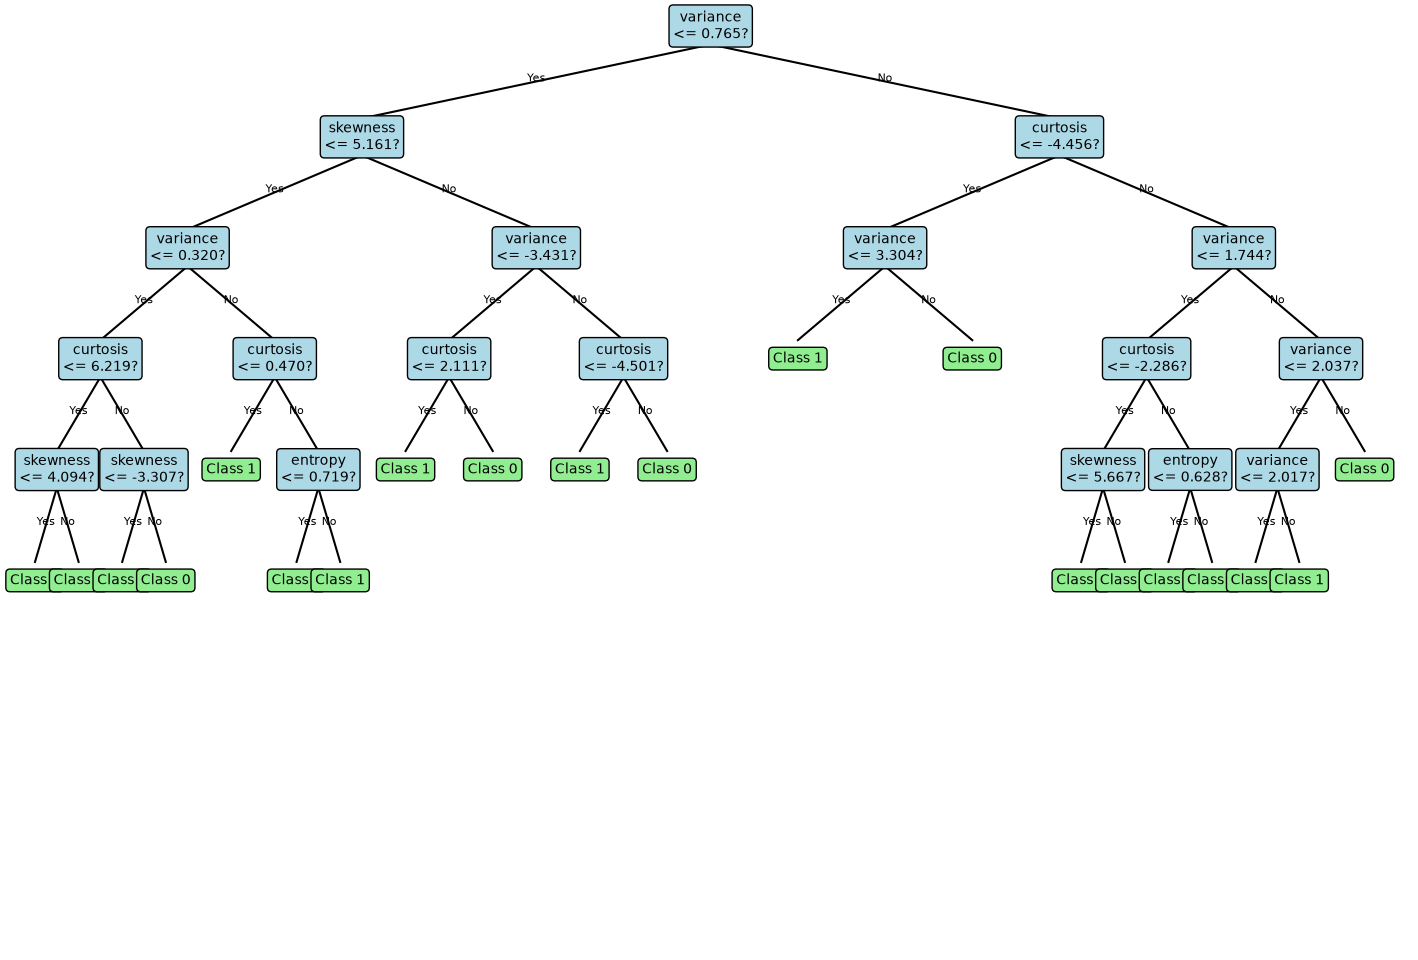

In [19]:

def plot_custom_tree(node, feature_names, ax, x=0.5, y=1.0,
                     x_span=0.25, y_step=0.12):
    if "feature" not in node:
        ax.text(
            x, y, f"Class {node['prediction']}",
            ha="center", va="center",
            bbox=dict(boxstyle="round", facecolor="lightgreen"),
            transform=ax.transAxes
        )
        return

    feature = feature_names[node["feature"]]
    threshold = node["threshold"]

    ax.text(
        x, y, f"{feature}\n<= {threshold:.3f}?",
        ha="center", va="center",
        bbox=dict(boxstyle="round", facecolor="lightblue"),
        transform=ax.transAxes
    )

    child_y = y - y_step

    for child_x, child, label in [
        (x - x_span, node["left"], "Yes"),
        (x + x_span, node["right"], "No")
    ]:
        ax.plot(
            [x, child_x], [y - 0.02, child_y + 0.02],
            color="black", transform=ax.transAxes
        )
        ax.text(
            (x + child_x) / 2, (y + child_y) / 2,
            label, fontsize=8, ha="center",
            transform=ax.transAxes
        )
        plot_custom_tree(
            child, feature_names, ax,
            child_x, child_y, x_span / 2, y_step
        )


fig, ax = plt.subplots(figsize=(18, 12))
ax.axis("off")

plot_custom_tree(tree.tree, feature_names, ax)
plt.show()


In [20]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    random_state=42
)

sklearn_tree.fit(X_train, y_train)

y_pred_sklearn = sklearn_tree.predict(X_test)

print("Scratch Tree Accuracy:", accuracy_score(y_test, y_pred))
print("Scikit-learn Tree Accuracy:", accuracy_score(y_test, y_pred_sklearn))

print("\nScikit-learn classification report:")
print(classification_report(y_test, y_pred_sklearn))


Scratch Tree Accuracy: 0.9854545454545455
Scikit-learn Tree Accuracy: 0.9927272727272727

Scikit-learn classification report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       153
           1       0.98      1.00      0.99       122

    accuracy                           0.99       275
   macro avg       0.99      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



Depth=   1 | Train=0.8423 | Test=0.8291
Depth=   2 | Train=0.9088 | Test=0.8909
Depth=   3 | Train=0.9435 | Test=0.9236
Depth=   5 | Train=0.9945 | Test=0.9927
Depth=  10 | Train=1.0000 | Test=0.9927
Depth=None | Train=1.0000 | Test=0.9927


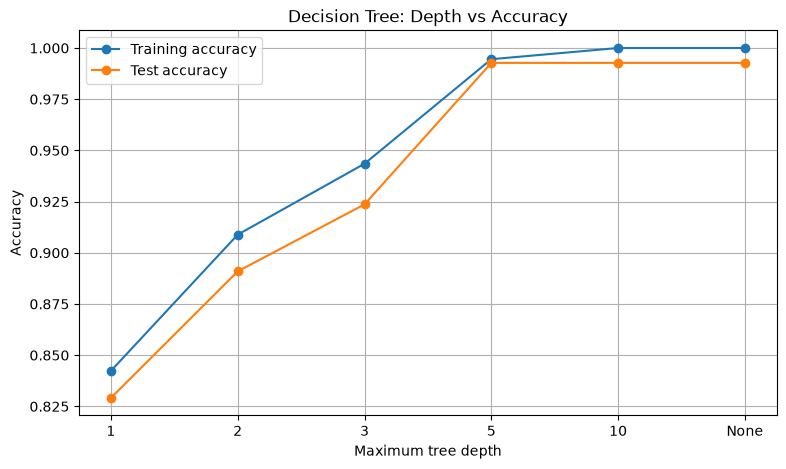

In [21]:

depths = [1, 2, 3, 5, 10, None]

train_accuracies = []
test_accuracies = []

for depth in depths:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracies.append(
        accuracy_score(y_train, model.predict(X_train))
    )
    test_accuracies.append(
        accuracy_score(y_test, model.predict(X_test))
    )

for depth, train_acc, test_acc in zip(
    depths, train_accuracies, test_accuracies
):
    print(
        f"Depth={str(depth):>4} | "
        f"Train={train_acc:.4f} | "
        f"Test={test_acc:.4f}"
    )

plt.figure(figsize=(9, 5))
plt.plot(range(len(depths)), train_accuracies, marker="o",
         label="Training accuracy")
plt.plot(range(len(depths)), test_accuracies, marker="o",
         label="Test accuracy")
plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Depth vs Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [22]:

for depth in [5, 10, None]:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"\nDepth: {depth}")
    print(f"Actual tree depth: {model.get_depth()}")
    print(f"Number of leaves: {model.get_n_leaves()}")
    print(f"Training accuracy: {train_acc:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")



Depth: 5
Actual tree depth: 5
Number of leaves: 20
Training accuracy: 0.9945
Test accuracy: 0.9927

Depth: 10
Actual tree depth: 7
Number of leaves: 25
Training accuracy: 1.0000
Test accuracy: 0.9927

Depth: None
Actual tree depth: 7
Number of leaves: 25
Training accuracy: 1.0000
Test accuracy: 0.9927


In [23]:

def entropy(labels):
    if len(labels) == 0:
        return 0.0

    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / len(labels)
    probabilities = probabilities[probabilities > 0]

    return -np.sum(
        probabilities * np.log2(probabilities)
    )


In [24]:

def information_gain(parent_labels, left_labels, right_labels):
    n = len(parent_labels)

    if n == 0:
        return 0.0

    left_weight = len(left_labels) / n
    right_weight = len(right_labels) / n

    parent_entropy = entropy(parent_labels)

    children_entropy = (
        left_weight * entropy(left_labels)
        + right_weight * entropy(right_labels)
    )

    return parent_entropy - children_entropy


In [25]:

def find_best_split_entropy(X, y):
    best_split = None
    best_gain = -1.0

    for feature_index in range(X.shape[1]):
        values = np.unique(X[:, feature_index])
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            feature_values = X[:, feature_index]

            left_mask = feature_values <= threshold
            right_mask = feature_values > threshold

            if not np.any(left_mask) or not np.any(right_mask):
                continue

            gain = information_gain(
                y,
                y[left_mask],
                y[right_mask]
            )

            if gain > best_gain:
                best_gain = gain
                best_split = {
                    "feature_index": feature_index,
                    "threshold": threshold,
                    "information_gain": gain,
                    "left_count": int(np.sum(left_mask)),
                    "right_count": int(np.sum(right_mask))
                }

    return best_split


In [26]:

best_entropy_split = find_best_split_entropy(X_train, y_train)

print("Best entropy-based split:")
print(best_entropy_split)


Best entropy-based split:
{'feature_index': 0, 'threshold': np.float64(0.7651), 'information_gain': np.float64(0.40280462579181764), 'left_count': 593, 'right_count': 504}


In [27]:

criteria = ["gini", "entropy"]

for criterion in criteria:
    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=5,
        min_samples_split=2,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )
    test_acc = accuracy_score(
        y_test, model.predict(X_test)
    )

    print(f"\nCriterion: {criterion}")
    print("Actual depth:", model.get_depth())
    print("Number of leaves:", model.get_n_leaves())
    print(f"Training accuracy: {train_acc:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")



Criterion: gini
Actual depth: 5
Number of leaves: 20
Training accuracy: 0.9945
Test accuracy: 0.9927

Criterion: entropy
Actual depth: 5
Number of leaves: 14
Training accuracy: 0.9973
Test accuracy: 0.9855


In [28]:
X_2d = df[["variance", "skewness"]].values
y_2d = df["class"].values

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

tree_2d = DecisionTreeScratch(
    max_depth=5,
    min_samples_split=2
)

tree_2d.fit(X_train_2d, y_train_2d)

y_pred_2d = tree_2d.predict(X_test_2d)

print("Number of features:", X_train_2d.shape[1])
print("Training samples:", len(X_train_2d))
print("Test samples:", len(X_test_2d))
print("2D scratch tree accuracy:", accuracy_score(y_test_2d, y_pred_2d))

Number of features: 2
Training samples: 1097
Test samples: 275
2D scratch tree accuracy: 0.9309090909090909


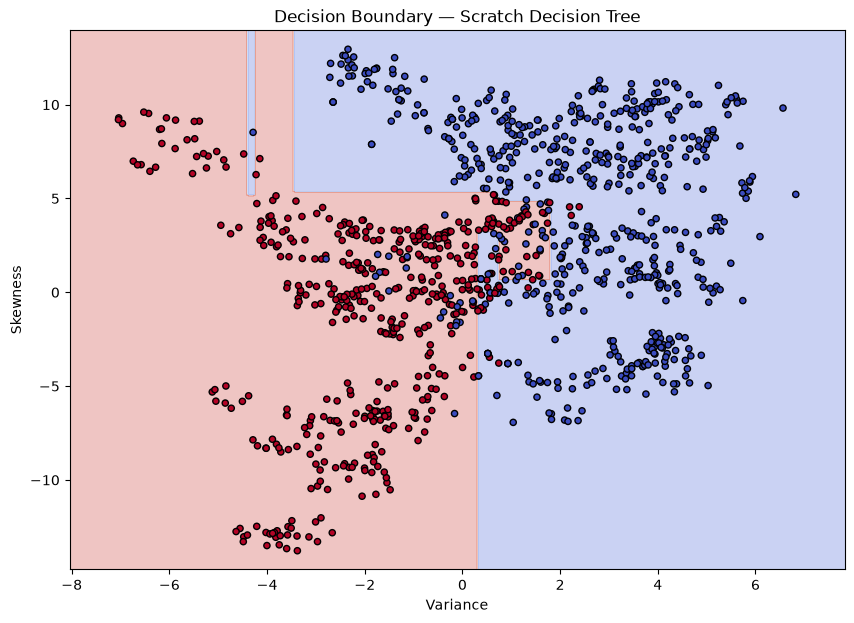

In [29]:
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

Z = tree_2d.predict(grid_points)
Z = Z.reshape(xx.shape)
plt.figure(figsize=(10, 7))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train_2d,
    cmap="coolwarm",
    edgecolors="black",
    s=20
)

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Decision Boundary — Scratch Decision Tree")
plt.show()

Part B

In [30]:
feature_names = ["variance", "skewness", "curtosis", "entropy"]

print("Feature statistics before scaling:\n")

for i, name in enumerate(feature_names):
    print(f"{name}:")
    print(f"  Minimum: {X_train[:, i].min():.4f}")
    print(f"  Maximum: {X_train[:, i].max():.4f}")
    print(f"  Mean:    {X_train[:, i].mean():.4f}")
    print(f"  Std:     {X_train[:, i].std():.4f}")
    print()

Feature statistics before scaling:

variance:
  Minimum: -7.0421
  Maximum: 6.8248
  Mean:    0.4635
  Std:     2.8395

skewness:
  Minimum: -13.7731
  Maximum: 12.9516
  Mean:    1.8728
  Std:     5.9046

curtosis:
  Minimum: -5.2613
  Maximum: 17.9274
  Mean:    1.4092
  Std:     4.3553

entropy:
  Minimum: -8.5482
  Maximum: 2.1353
  Mean:    -1.2137
  Std:     2.1105



In [31]:
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_std[X_std == 0] = 1

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

print("Training means after scaling:")
print(X_train_scaled.mean(axis=0).round(4))

print("\nTraining standard deviations after scaling:")
print(X_train_scaled.std(axis=0).round(4))

Training means after scaling:
[-0. -0. -0.  0.]

Training standard deviations after scaling:
[1. 1. 1. 1.]


In [32]:
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Original training labels:", np.unique(y_train))
print("SVM training labels:", np.unique(y_train_svm))

print("\nTraining label counts:")
print("-1:", np.sum(y_train_svm == -1))
print("+1:", np.sum(y_train_svm == 1))

Original training labels: [0 1]
SVM training labels: [-1  1]

Training label counts:
-1: 609
+1: 488


In [33]:
def hinge_loss(X, y, w, b):
    scores = X @ w + b
    margins = y * scores
    losses = np.maximum(0, 1 - margins)
    return np.mean(losses)


# A small example with two features
X_example = np.array([
    [2.0, 1.0],
    [0.5, 1.0],
    [-1.0, -1.0]
])

y_example = np.array([1, 1, -1])

w_example = np.array([1.0, 1.0])
b_example = 0.0

print("Mean hinge loss:", hinge_loss(
    X_example, y_example, w_example, b_example
))

Mean hinge loss: 0.0


In [34]:
def svm_objective(X, y, w, b, C=1.0):
    regularization = 0.5 * np.sum(w ** 2)
    scores = X @ w + b
    margins = y * scores
    losses = np.maximum(0, 1 - margins)
    average_hinge_loss = np.mean(losses)
    objective = regularization + C * average_hinge_loss

    return objective

In [35]:
def svm_subgradients(X, y, w, b, C=1.0):
    n = len(y)

    scores = X @ w + b
    margins = y * scores
    violating = margins < 1
    dw = w.copy()

    if np.any(violating):
        dw -= (C / n) * (X[violating].T @ y[violating])
        db = -(C / n) * np.sum(y[violating])
    else:
        db = 0.0

    return dw, db

In [37]:
def train_svm(X, y, C=1.0, learning_rate=0.001, n_iterations=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0

    loss_history = []

    for iteration in range(n_iterations):
        dw, db = svm_subgradients(X, y, w, b, C)

        w -= learning_rate * dw
        b -= learning_rate * db
        current_loss = svm_objective(X, y, w, b, C)
        loss_history.append(current_loss)

    return w, b, loss_history

In [38]:
w_svm, b_svm, loss_history = train_svm(
    X_train_scaled,
    y_train_svm,
    C=1.0,
    learning_rate=0.001,
    n_iterations=1000
)

print("Learned weights:", w_svm)
print("Learned bias:", b_svm)
print("Initial objective:", loss_history[0])
print("Final objective:", loss_history[-1])

Learned weights: [-0.41797038 -0.24048154  0.04904751 -0.01181448]
Learned bias: -0.1148277119416592
Initial objective: 0.9992600661631305
Final objective: 0.7054174225059524


In [39]:
def predict_svm(X, w, b):
    scores = X @ w + b
    return np.where(scores >= 0, 1, -1)


# Predict on unseen test data
y_pred_svm = predict_svm(X_test_scaled, w_svm, b_svm)

# Calculate accuracy
accuracy_svm = np.mean(y_pred_svm == y_test_svm)

print("Scratch SVM test accuracy:", accuracy_svm)
print("Correct predictions:", np.sum(y_pred_svm == y_test_svm))
print("Incorrect predictions:", np.sum(y_pred_svm != y_test_svm))

Scratch SVM test accuracy: 0.8727272727272727
Correct predictions: 240
Incorrect predictions: 35


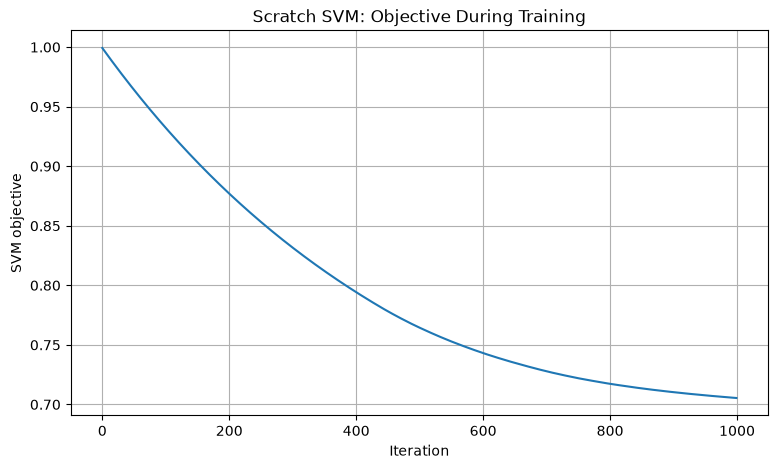

In [40]:
plt.figure(figsize=(9, 5))
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("SVM objective")
plt.title("Scratch SVM: Objective During Training")
plt.grid(True)
plt.show()

In [41]:
iteration_values = [500, 1000, 2000, 5000]

for n_iter in iteration_values:
    w_temp, b_temp, history = train_svm(
        X_train_scaled,
        y_train_svm,
        C=1.0,
        learning_rate=0.001,
        n_iterations=n_iter
    )

    y_pred_temp = predict_svm(X_test_scaled, w_temp, b_temp)
    accuracy = np.mean(y_pred_temp == y_test_svm)

    print(f"Iterations: {n_iter:4d}")
    print(f"  Final objective: {history[-1]:.4f}")
    print(f"  Test accuracy:   {accuracy:.4f}")

Iterations:  500
  Final objective: 0.7647
  Test accuracy:   0.8727
Iterations: 1000
  Final objective: 0.7054
  Test accuracy:   0.8727
Iterations: 2000
  Final objective: 0.6886
  Test accuracy:   0.8691
Iterations: 5000
  Final objective: 0.6856
  Test accuracy:   0.8800


In [42]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

for C_value in C_values:
    w_temp, b_temp, history = train_svm(
        X_train_scaled,
        y_train_svm,
        C=C_value,
        learning_rate=0.001,
        n_iterations=5000
    )

    train_pred = predict_svm(X_train_scaled, w_temp, b_temp)
    test_pred = predict_svm(X_test_scaled, w_temp, b_temp)

    train_accuracy = np.mean(train_pred == y_train_svm)
    test_accuracy = np.mean(test_pred == y_test_svm)

    print(f"C = {C_value}")
    print(f"  Final objective: {history[-1]:.4f}")
    print(f"  Training accuracy: {train_accuracy:.4f}")
    print(f"  Test accuracy: {test_accuracy:.4f}")

C = 0.01
  Final objective: 0.0100
  Training accuracy: 0.8049
  Test accuracy: 0.8255
C = 0.1
  Final objective: 0.0958
  Training accuracy: 0.8049
  Test accuracy: 0.8255
C = 1.0
  Final objective: 0.6856
  Training accuracy: 0.8560
  Test accuracy: 0.8800
C = 10.0
  Final objective: 2.7616
  Training accuracy: 0.9772
  Test accuracy: 0.9709
C = 100.0
  Final objective: 9.9868
  Training accuracy: 0.9854
  Test accuracy: 0.9709


In [43]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

sklearn_svm = LinearSVC(
    C=10.0,
    max_iter=10000,
    random_state=42
)

sklearn_svm.fit(X_train_scaled, y_train_svm)

y_pred_sklearn_svm = sklearn_svm.predict(X_test_scaled)

print("Scratch SVM accuracy:",
      accuracy_score(y_test_svm, predict_svm(
          X_test_scaled, w_temp, b_temp
      )))

print("Scikit-learn LinearSVC accuracy:",
      accuracy_score(y_test_svm, y_pred_sklearn_svm))

print("\nClassification report:")
print(classification_report(y_test_svm, y_pred_sklearn_svm))

Scratch SVM accuracy: 0.9709090909090909
Scikit-learn LinearSVC accuracy: 0.9854545454545455

Classification report:
              precision    recall  f1-score   support

          -1       1.00      0.97      0.99       153
           1       0.97      1.00      0.98       122

    accuracy                           0.99       275
   macro avg       0.98      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



In [44]:
# Select variance and skewness only
X_train_2d_scaled = X_train_scaled[:, :2]
X_test_2d_scaled = X_test_scaled[:, :2]

# Train a two-feature scratch SVM
w_2d, b_2d, loss_2d = train_svm(
    X_train_2d_scaled,
    y_train_svm,
    C=10.0,
    learning_rate=0.001,
    n_iterations=5000
)

# Evaluate the two-feature model
y_pred_2d_svm = predict_svm(
    X_test_2d_scaled,
    w_2d,
    b_2d
)

print("Number of features:", X_train_2d_scaled.shape[1])
print(
    "2D scratch SVM test accuracy:",
    accuracy_score(y_test_svm, y_pred_2d_svm)
)
print("Weights:", w_2d)
print("Bias:", b_2d)

Number of features: 2
2D scratch SVM test accuracy: 0.8872727272727273
Weights: [-1.05587595 -0.60675967]
Bias: -0.2549498632634329


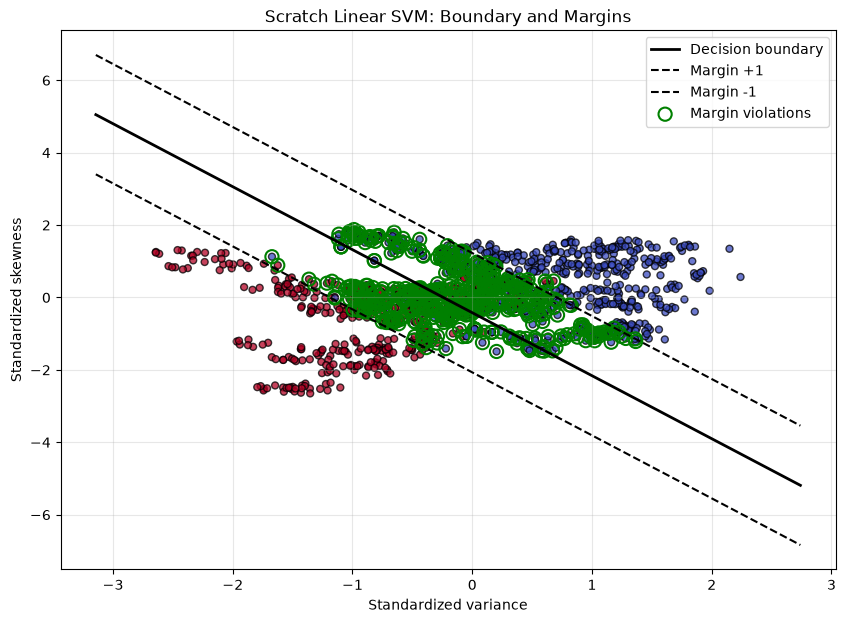

In [45]:
# Use standardized variance and skewness
x_min = X_train_2d_scaled[:, 0].min() - 0.5
x_max = X_train_2d_scaled[:, 0].max() + 0.5
xx = np.linspace(x_min, x_max, 300)

# Boundary and margin equations:
# w1*x1 + w2*x2 + b = score
# x2 = (score - b - w1*x1) / w2

decision_boundary = (-b_2d - w_2d[0] * xx) / w_2d[1]
margin_positive = (1 - b_2d - w_2d[0] * xx) / w_2d[1]
margin_negative = (-1 - b_2d - w_2d[0] * xx) / w_2d[1]

plt.figure(figsize=(10, 7))

# Training samples
plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=y_train_svm,
    cmap="coolwarm",
    edgecolors="black",
    s=25,
    alpha=0.75
)

# Decision boundary and margins
plt.plot(xx, decision_boundary, "k-", linewidth=2, label="Decision boundary")
plt.plot(xx, margin_positive, "k--", label="Margin +1")
plt.plot(xx, margin_negative, "k--", label="Margin -1")

# Highlight training samples inside or beyond the wrong margin
train_scores = X_train_2d_scaled @ w_2d + b_2d
train_margins = y_train_svm * train_scores
violating = train_margins < 1

plt.scatter(
    X_train_2d_scaled[violating, 0],
    X_train_2d_scaled[violating, 1],
    s=90,
    facecolors="none",
    edgecolors="green",
    linewidths=1.5,
    label="Margin violations"
)

plt.xlabel("Standardized variance")
plt.ylabel("Standardized skewness")
plt.title("Scratch Linear SVM: Boundary and Margins")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [46]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

sklearn_svm_2d = LinearSVC(
    C=10.0,
    max_iter=10000,
    random_state=42
)

sklearn_svm_2d.fit(X_train_2d_scaled, y_train_svm)

y_pred_sklearn_2d = sklearn_svm_2d.predict(X_test_2d_scaled)

print("Scratch SVM accuracy:",
      accuracy_score(y_test_svm, y_pred_2d_svm))

print("Scikit-learn 2D SVM accuracy:",
      accuracy_score(y_test_svm, y_pred_sklearn_2d))

print("\nScikit-learn weights:", sklearn_svm_2d.coef_[0])
print("Scikit-learn bias:", sklearn_svm_2d.intercept_[0])

Scratch SVM accuracy: 0.8872727272727273
Scikit-learn 2D SVM accuracy: 0.8763636363636363

Scikit-learn weights: [-1.02598596 -0.55824882]
Scikit-learn bias: -0.1343176464538587


Part C:

In [47]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.10,
    random_state=42
)

print("Feature shape:", X_moons.shape)
print("Target shape:", y_moons.shape)
print("Classes:", np.unique(y_moons))
print("Class counts:", np.bincount(y_moons))

Feature shape: (500, 2)
Target shape: (500,)
Classes: [0 1]
Class counts: [250 250]


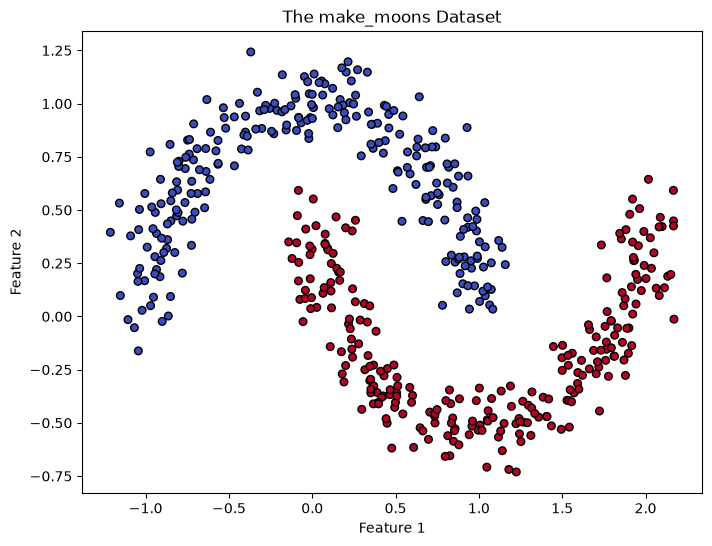

In [48]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="coolwarm",
    edgecolors="black",
    s=30
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("The make_moons Dataset")
plt.show()

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=42,
    stratify=y_moons
)
moon_scaler = StandardScaler()
X_moons_train_scaled = moon_scaler.fit_transform(X_moons_train)
X_moons_test_scaled = moon_scaler.transform(X_moons_test)
linear_moon_svm = SVC(kernel="linear", C=1.0)
linear_moon_svm.fit(X_moons_train_scaled, y_moons_train)

linear_moon_pred = linear_moon_svm.predict(X_moons_test_scaled)

print("Training samples:", len(X_moons_train))
print("Test samples:", len(X_moons_test))
print("Linear SVM test accuracy:",
      accuracy_score(y_moons_test, linear_moon_pred))

Training samples: 400
Test samples: 100
Linear SVM test accuracy: 0.86


In [50]:
kernels = ["linear", "poly", "rbf"]

for kernel_name in kernels:
    model = SVC(
        kernel=kernel_name,
        C=1.0,
        random_state=42
    )

    model.fit(X_moons_train_scaled, y_moons_train)

    train_pred = model.predict(X_moons_train_scaled)
    test_pred = model.predict(X_moons_test_scaled)

    print(f"\nKernel: {kernel_name}")
    print(f"Training accuracy: {accuracy_score(y_moons_train, train_pred):.4f}")
    print(f"Test accuracy:     {accuracy_score(y_moons_test, test_pred):.4f}")


Kernel: linear
Training accuracy: 0.8800
Test accuracy:     0.8600

Kernel: poly
Training accuracy: 0.8750
Test accuracy:     0.8600

Kernel: rbf
Training accuracy: 1.0000
Test accuracy:     1.0000


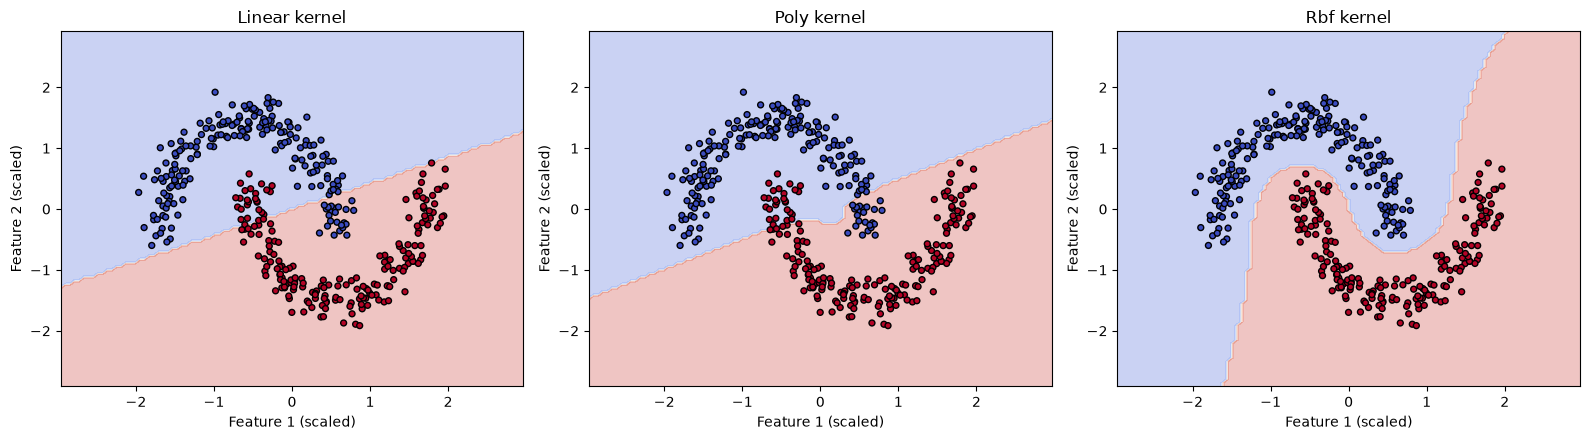

In [51]:
from sklearn.inspection import DecisionBoundaryDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, kernel_name in zip(axes, ["linear", "poly", "rbf"]):
    model = SVC(kernel=kernel_name, C=1.0, random_state=42)
    model.fit(X_moons_train_scaled, y_moons_train)

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_moons_train_scaled,
        response_method="predict",
        alpha=0.3,
        cmap="coolwarm",
        ax=ax
    )

    ax.scatter(
        X_moons_train_scaled[:, 0],
        X_moons_train_scaled[:, 1],
        c=y_moons_train,
        cmap="coolwarm",
        edgecolors="black",
        s=18
    )

    ax.set_title(f"{kernel_name.capitalize()} kernel")
    ax.set_xlabel("Feature 1 (scaled)")
    ax.set_ylabel("Feature 2 (scaled)")

plt.tight_layout()
plt.show()

In [52]:
gamma_values = [0.01, 0.1, 1, 10, 100]

gamma_results = []

for gamma_value in gamma_values:
    model = SVC(
        kernel="rbf",
        C=1.0,
        gamma=gamma_value
    )

    model.fit(X_moons_train_scaled, y_moons_train)

    train_pred = model.predict(X_moons_train_scaled)
    test_pred = model.predict(X_moons_test_scaled)

    train_acc = accuracy_score(y_moons_train, train_pred)
    test_acc = accuracy_score(y_moons_test, test_pred)

    gamma_results.append({
        "gamma": gamma_value,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

    print(f"\ngamma = {gamma_value}")
    print(f"Training accuracy: {train_acc:.4f}")
    print(f"Test accuracy:     {test_acc:.4f}")


gamma = 0.01
Training accuracy: 0.8550
Test accuracy:     0.8600

gamma = 0.1
Training accuracy: 0.8850
Test accuracy:     0.8900

gamma = 1
Training accuracy: 1.0000
Test accuracy:     1.0000

gamma = 10
Training accuracy: 1.0000
Test accuracy:     1.0000

gamma = 100
Training accuracy: 1.0000
Test accuracy:     0.9900


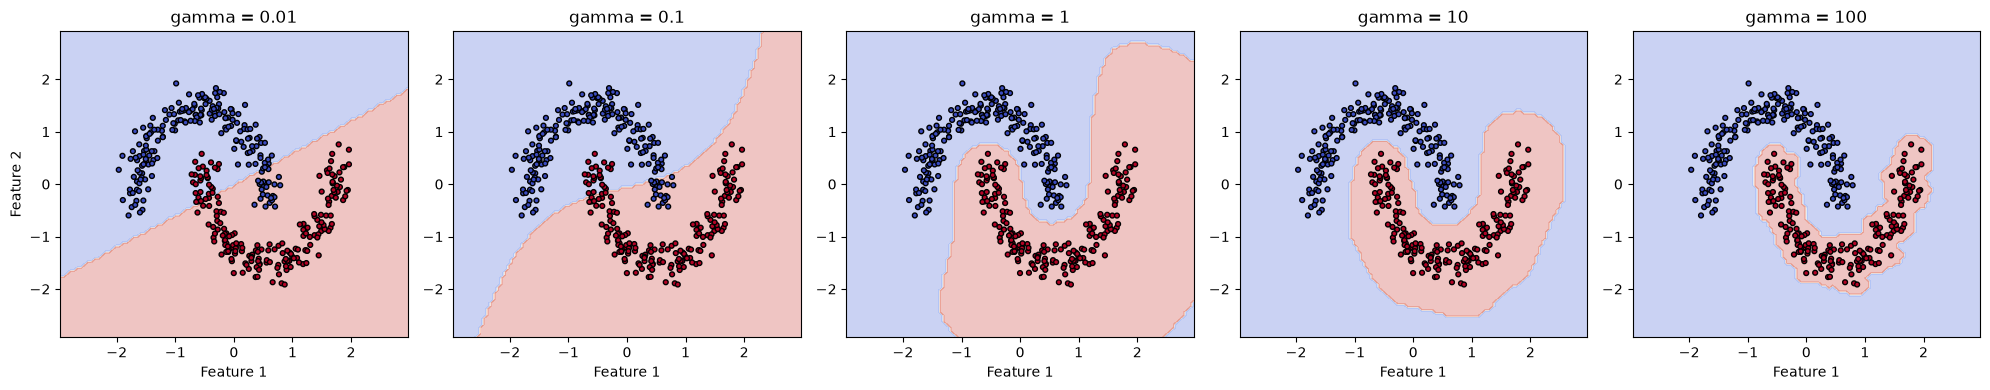

In [53]:
gamma_values = [0.01, 0.1, 1, 10, 100]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, gamma_value in zip(axes, gamma_values):
    model = SVC(
        kernel="rbf",
        C=1.0,
        gamma=gamma_value
    )
    model.fit(X_moons_train_scaled, y_moons_train)

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_moons_train_scaled,
        response_method="predict",
        alpha=0.3,
        cmap="coolwarm",
        ax=ax
    )

    ax.scatter(
        X_moons_train_scaled[:, 0],
        X_moons_train_scaled[:, 1],
        c=y_moons_train,
        cmap="coolwarm",
        edgecolors="black",
        s=12
    )

    ax.set_title(f"gamma = {gamma_value}")
    ax.set_xlabel("Feature 1")

axes[0].set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

Part D:

In [54]:
import time
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

def evaluate_model(name, model, Xtr, ytr, Xte, yte):
    start = time.perf_counter()
    model.fit(Xtr, ytr)
    train_time = time.perf_counter() - start
    start = time.perf_counter()
    predictions = model.predict(Xte)
    predict_time = time.perf_counter() - start

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(yte, predictions),
        "Precision": precision_score(
            yte, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            yte, predictions, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            yte, predictions, average="weighted", zero_division=0
        ),
        "Training time (s)": train_time,
        "Prediction time (s)": predict_time
    })

    return model

scratch_tree_final = evaluate_model(
    "Scratch Decision Tree",
    DecisionTreeScratch(max_depth=5, min_samples_split=2),
    X_train, y_train, X_test, y_test
)
sklearn_tree_final = evaluate_model(
    "Sklearn Decision Tree",
    DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        random_state=42
    ),
    X_train, y_train, X_test, y_test
)
start = time.perf_counter()
w_scratch_final, b_scratch_final, loss_final = train_svm(
    X_train_scaled,
    y_train_svm,
    C=10.0,
    learning_rate=0.001,
    n_iterations=5000
)
scratch_train_time = time.perf_counter() - start

start = time.perf_counter()
scratch_svm_pred = predict_svm(
    X_test_scaled, w_scratch_final, b_scratch_final
)
scratch_predict_time = time.perf_counter() - start
scratch_svm_pred_original = np.where(scratch_svm_pred == -1, 0, 1)

results.append({
    "Model": "Scratch Linear SVM",
    "Accuracy": accuracy_score(y_test, scratch_svm_pred_original),
    "Precision": precision_score(
        y_test, scratch_svm_pred_original, average="weighted", zero_division=0
    ),
    "Recall": recall_score(
        y_test, scratch_svm_pred_original, average="weighted", zero_division=0
    ),
    "F1-score": f1_score(
        y_test, scratch_svm_pred_original, average="weighted", zero_division=0
    ),
    "Training time (s)": scratch_train_time,
    "Prediction time (s)": scratch_predict_time
})


sklearn_linear_final = evaluate_model(
    "Sklearn Linear SVM",
    LinearSVC(C=10.0, max_iter=10000, random_state=42),
    X_train_scaled, y_train, X_test_scaled, y_test
)

sklearn_rbf_final = evaluate_model(
    "Sklearn RBF SVM",
    SVC(kernel="rbf", C=10.0, gamma="scale"),
    X_train_scaled, y_train, X_test_scaled, y_test
)

comparison_df = pd.DataFrame(results)

print("FINAL MODEL COMPARISON")
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "Training time (s)": "{:.6f}",
        "Prediction time (s)": "{:.6f}"
    })
)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Scratch Decision Tree,0.9855,0.9859,0.9855,0.9855,0.318057,0.000107
1,Sklearn Decision Tree,0.9927,0.9928,0.9927,0.9927,0.001198,0.000057
2,Scratch Linear SVM,0.9709,0.9727,0.9709,0.9710,0.142018,0.000026
3,Sklearn Linear SVM,0.9855,0.9859,0.9855,0.9855,0.000482,0.000063
4,Sklearn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.001204,0.000307


### Conclusion

In this lab, decision tree and support vector machine classifiers were implemented and evaluated on the Banknote Authentication dataset. The scratch decision tree achieved 98.55% test accuracy, while the scikit-learn decision tree achieved 99.27%. The scratch linear SVM achieved 97.09%, compared with 98.55% for scikit-learn's LinearSVC. The RBF SVM achieved 100% accuracy on the selected test split.

The experiment demonstrated that decision trees provide interpretable, rule-based decisions, while SVMs use margin maximization to construct separating boundaries. Feature standardization was important for SVM training, and nonlinear kernels enabled more flexible decision boundaries. The scratch implementations helped illustrate the underlying algorithms, while scikit-learn provided faster training.

Although the RBF SVM achieved the highest test accuracy in this experiment, further validation using cross-validation and an independent holdout set would be needed before concluding that it generalizes best to unseen banknote data.
